In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

In [2]:
df = pd.read_csv("Crop_recommendation.csv")
df

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice
...,...,...,...,...,...,...,...,...
2195,107,34,32,26.774637,66.413269,6.780064,177.774507,coffee
2196,99,15,27,27.417112,56.636362,6.086922,127.924610,coffee
2197,118,33,30,24.131797,67.225123,6.362608,173.322839,coffee
2198,117,32,34,26.272418,52.127394,6.758793,127.175293,coffee


In [3]:
df["label"].value_counts()

label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64

In [4]:
df["label"].unique()

<StringArray>
[       'rice',       'maize',    'chickpea', 'kidneybeans',  'pigeonpeas',
   'mothbeans',    'mungbean',   'blackgram',      'lentil', 'pomegranate',
      'banana',       'mango',      'grapes',  'watermelon',   'muskmelon',
       'apple',      'orange',      'papaya',     'coconut',      'cotton',
        'jute',      'coffee']
Length: 22, dtype: str

In [5]:
df.isna().sum()

N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


In [8]:
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


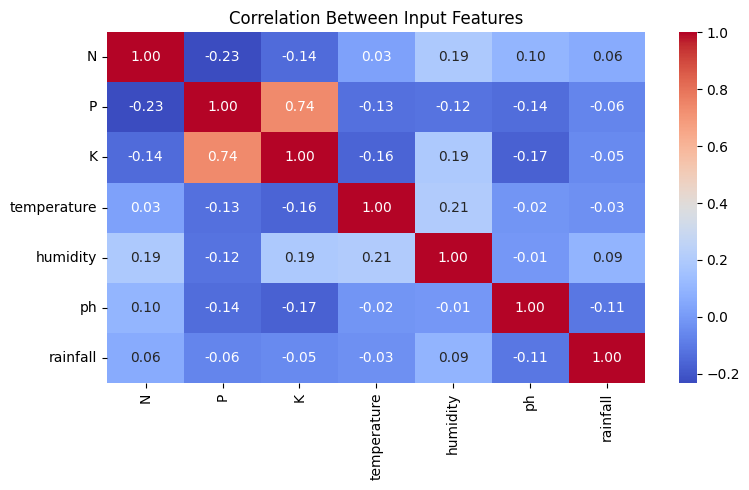

In [9]:
plt.figure(figsize=(8, 5))

correlation = df.drop(columns="label").corr()

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Between Input Features")
plt.tight_layout()
plt.show()

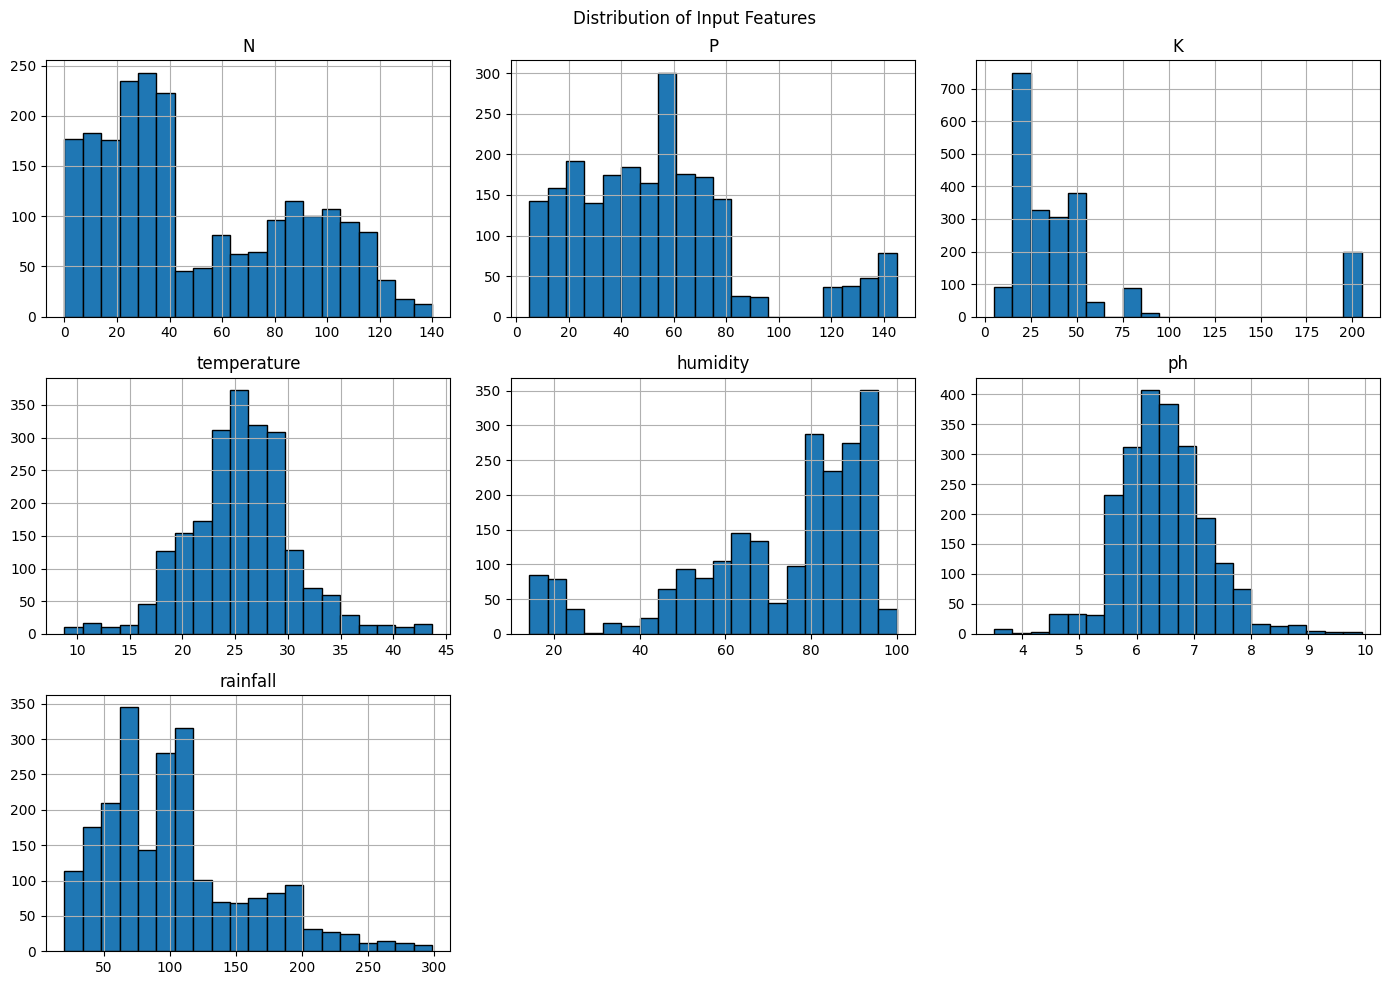

In [10]:
numerical_columns = [
    "N", "P", "K",
    "temperature", "humidity",
    "ph", "rainfall"
]

df[numerical_columns].hist(
    figsize=(14, 10),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Input Features")
plt.tight_layout()
plt.show()

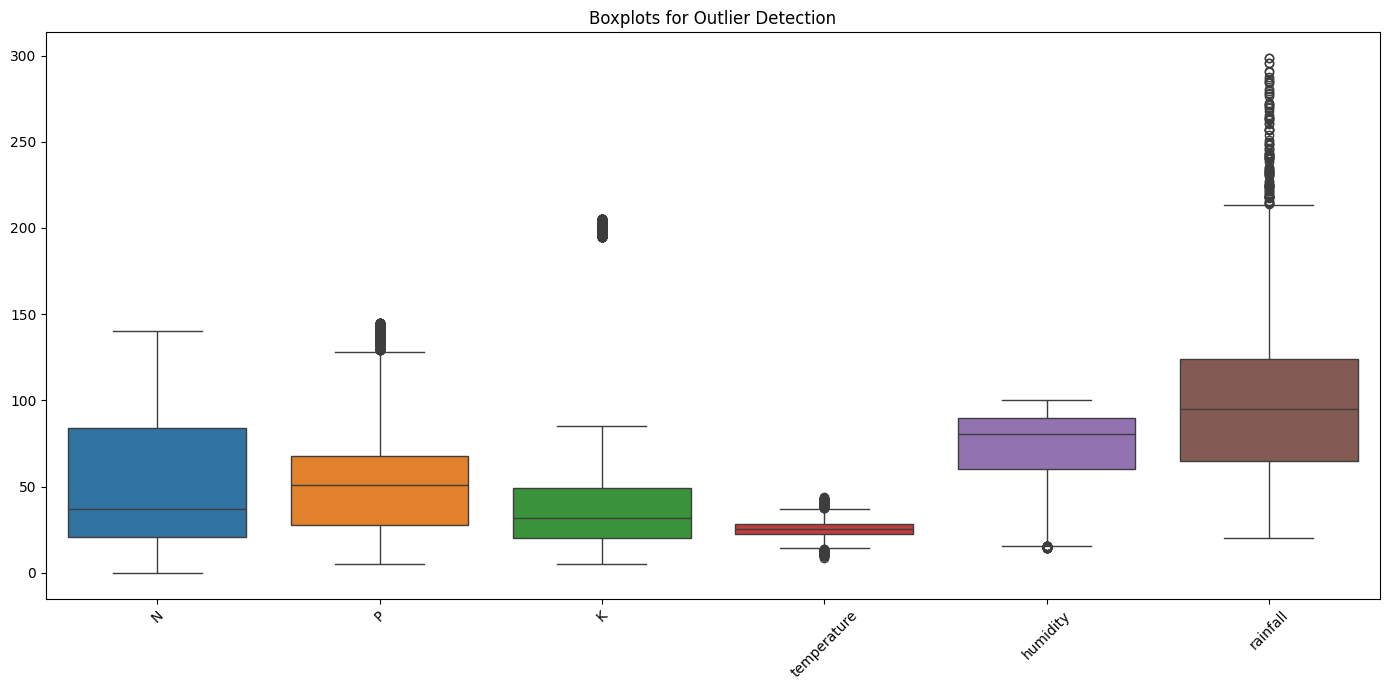

In [11]:
numerical_columns = [
    "N", "P", "K",
    "temperature", "humidity",
    "rainfall"
]

plt.figure(figsize=(14, 7))
sns.boxplot(data=df[numerical_columns])
plt.title("Boxplots for Outlier Detection")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
X = df.drop(["label"],axis=1)
y = df["label"]

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [14]:

model1 = LogisticRegression(max_iter=10500,random_state = 42)

In [15]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

model2 = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

model3 = GaussianNB()

model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)

y_pred1 = model1.predict(X_test)
y_pred2 = model2.predict(X_test)
y_pred3 = model3.predict(X_test)

acc_lr_before = accuracy_score(y_test, y_pred1)
acc_rf_before = accuracy_score(y_test, y_pred2)
acc_nb_before = accuracy_score(y_test, y_pred3)

print("Logistic Regression:", acc_lr_before)
print("Random Forest:", acc_rf_before)
print("Gaussian Naive Bayes:", acc_nb_before)

Logistic Regression: 0.975
Random Forest: 0.9931818181818182
Gaussian Naive Bayes: 0.9954545454545455


In [16]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

lr_cv_scores = cross_val_score(model1, X_train, y_train,cv=cv, scoring="accuracy")

rf_cv_scores = cross_val_score(model2, X_train, y_train,cv=cv, scoring="accuracy")

nb_cv_scores = cross_val_score(model3, X_train, y_train,cv=cv, scoring="accuracy")

print("Logistic Regression CV scores:", lr_cv_scores)
print("Logistic Regression mean CV accuracy:", lr_cv_scores.mean())

print("Random Forest CV scores:", rf_cv_scores)
print("Random Forest mean CV accuracy:", rf_cv_scores.mean())

print("Naive Bayes CV scores:", nb_cv_scores)
print("Naive Bayes mean CV accuracy:", nb_cv_scores.mean())

Logistic Regression CV scores: [0.99715909 0.97727273 0.98011364 0.98295455 0.98295455]
Logistic Regression mean CV accuracy: 0.984090909090909
Random Forest CV scores: [0.99715909 0.98863636 0.99147727 0.99715909 0.99431818]
Random Forest mean CV accuracy: 0.99375
Naive Bayes CV scores: [0.99715909 0.99715909 0.99431818 0.99147727 0.99715909]
Naive Bayes mean CV accuracy: 0.9954545454545455


In [22]:
from sklearn.model_selection import GridSearchCV

lr_params = {
    "C": [ 0.1, 1, 10, 100],
    "solver": ["lbfgs"],
    "max_iter": [500 , 1000 ,1500]
}

lr_grid = GridSearchCV(
    estimator=LogisticRegression(random_state=42),
    param_grid=lr_params,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)



In [24]:
lr_grid.fit(X_train, y_train)

best_lr = lr_grid.best_estimator_

print("Best Logistic Regression parameters:")
print(lr_grid.best_params_)

print("Best Logistic Regression CV accuracy:")
print(lr_grid.best_score_)

lr_tuned_pred = best_lr.predict(X_test)
lr_tuned_accuracy = accuracy_score(y_test, lr_tuned_pred)

print("Tuned Logistic Regression test accuracy:", lr_tuned_accuracy)

Best Logistic Regression parameters:
{'C': 0.1, 'max_iter': 1500, 'solver': 'lbfgs'}
Best Logistic Regression CV accuracy:
0.9818181818181817
Tuned Logistic Regression test accuracy: 0.9727272727272728


C:\Users\rs555\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [27]:
rf_params = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20, 30]
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=rf_params,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

best_rf = rf_grid.best_estimator_

print("Best Random Forest parameters:")
print(rf_grid.best_params_)

print("Best Random Forest CV accuracy:")
print(rf_grid.best_score_)

rf_tuned_pred = best_rf.predict(X_test)
rf_tuned_accuracy = accuracy_score(y_test, rf_tuned_pred)

print("Tuned Random Forest test accuracy:", rf_tuned_accuracy)

Best Random Forest parameters:
{'max_depth': None, 'n_estimators': 100}
Best Random Forest CV accuracy:
0.99375
Tuned Random Forest test accuracy: 0.9931818181818182


In [28]:
nb_params = {
    "var_smoothing": [
        1e-12, 1e-11, 1e-10,
        1e-9, 1e-8, 1e-7,
        1e-6, 1e-5
    ]
}

nb_grid = GridSearchCV(
    estimator=GaussianNB(),
    param_grid=nb_params,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

nb_grid.fit(X_train, y_train)

best_nb = nb_grid.best_estimator_

print("Best Naive Bayes parameters:")
print(nb_grid.best_params_)

print("Best Naive Bayes CV accuracy:")
print(nb_grid.best_score_)

nb_tuned_pred = best_nb.predict(X_test)
nb_tuned_accuracy = accuracy_score(y_test, nb_tuned_pred)

print("Tuned Naive Bayes test accuracy:", nb_tuned_accuracy)

Best Naive Bayes parameters:
{'var_smoothing': 1e-12}
Best Naive Bayes CV accuracy:
0.9954545454545455
Tuned Naive Bayes test accuracy: 0.9954545454545455


                  Model  Before Tuning  After Tuning
0   Logistic Regression       0.975000      0.972727
1         Random Forest       0.993182      0.993182
2  Gaussian Naive Bayes       0.995455      0.995455


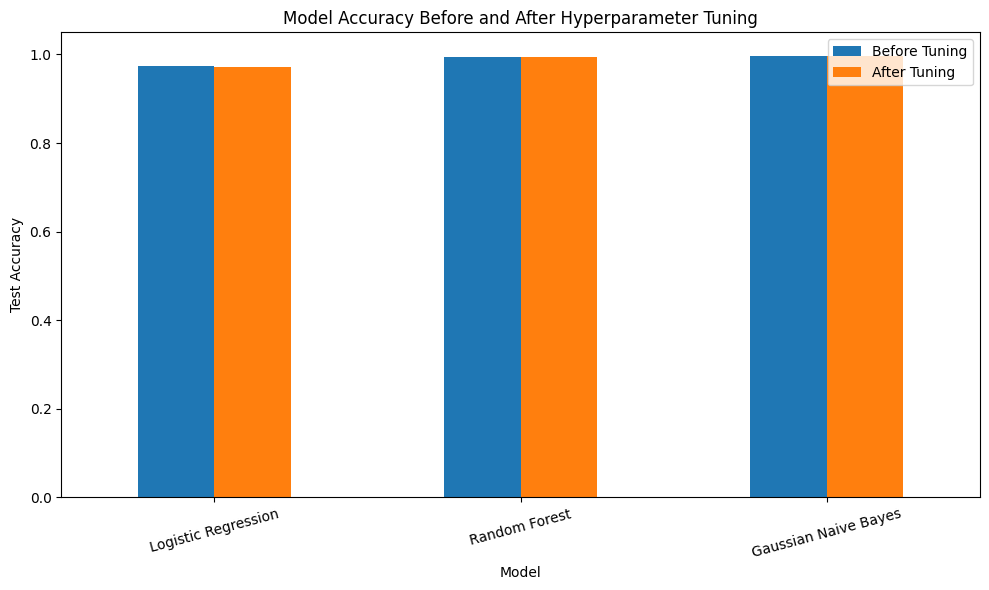

In [31]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gaussian Naive Bayes"
    ],
    "Before Tuning": [
        acc_lr_before,
        acc_rf_before,
        acc_nb_before
    ],
    "After Tuning": [
        lr_tuned_accuracy,
        rf_tuned_accuracy,
        nb_tuned_accuracy
    ]
})

print(comparison)

comparison.plot(
    x="Model",
    y=["Before Tuning", "After Tuning"],
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Accuracy Before and After Hyperparameter Tuning")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend()
plt.tight_layout()
plt.show()

In [38]:
from sklearn.metrics import classification_report

print("Logistic Regression")
print(classification_report(y_test, best_lr.predict(X_test)))

print("Random Forest")
print(classification_report(y_test, best_rf.predict(X_test)))

print("Naive Bayes")
print(classification_report(y_test, best_nb.predict(X_test)))

Logistic Regression
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        23
      banana       1.00      1.00      1.00        21
   blackgram       0.90      0.95      0.93        20
    chickpea       1.00      1.00      1.00        26
     coconut       1.00      1.00      1.00        27
      coffee       0.94      1.00      0.97        17
      cotton       0.94      1.00      0.97        17
      grapes       1.00      1.00      1.00        14
        jute       0.83      0.87      0.85        23
 kidneybeans       1.00      1.00      1.00        20
      lentil       0.92      1.00      0.96        11
       maize       1.00      0.95      0.98        21
       mango       1.00      1.00      1.00        19
   mothbeans       1.00      1.00      1.00        24
    mungbean       1.00      1.00      1.00        19
   muskmelon       1.00      1.00      1.00        17
      orange       1.00      1.00      1.00        14
      p

In [32]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gaussian Naive Bayes"
    ],
    "Best CV Accuracy": [
        lr_grid.best_score_,
        rf_grid.best_score_,
        nb_grid.best_score_
    ],
    "Test Accuracy": [
        lr_tuned_accuracy,
        rf_tuned_accuracy,
        nb_tuned_accuracy
    ]
})

print(results.sort_values("Test Accuracy", ascending=False))

                  Model  Best CV Accuracy  Test Accuracy
2  Gaussian Naive Bayes          0.995455       0.995455
1         Random Forest          0.993750       0.993182
0   Logistic Regression          0.981818       0.972727


In [33]:
import os
import joblib

if lr_tuned_accuracy >= rf_tuned_accuracy and lr_tuned_accuracy >= nb_tuned_accuracy:
    final_model = best_lr
    final_model_name = "Logistic Regression"

elif rf_tuned_accuracy >= lr_tuned_accuracy and rf_tuned_accuracy >= nb_tuned_accuracy:
    final_model = best_rf
    final_model_name = "Random Forest"

else:
    final_model = best_nb
    final_model_name = "Gaussian Naive Bayes"

os.makedirs("models", exist_ok=True)

joblib.dump(final_model, "models/best_crop_model.pkl")

print("Selected model:", final_model_name)
print("Test accuracy:", max(
    lr_tuned_accuracy,
    rf_tuned_accuracy,
    nb_tuned_accuracy
))

print("Saved to models/best_crop_model.pkl")

Selected model: Gaussian Naive Bayes
Test accuracy: 0.9954545454545455
Saved to models/best_crop_model.pkl
